# Random Forest Metabolomics Pipeline

### Imports and config loading

In [1]:
import os
import sys
import copy
from pathlib import Path
import yaml
from dotenv import load_dotenv

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_curve, auc, precision_recall_fscore_support
)
from sklearn.metrics import classification_report, confusion_matrix

pd.set_option('future.no_silent_downcasting', True)


class DotDict(dict):
    __getattr__ = dict.get
    __setattr__ = dict.__setitem__


def _to_dotdict(x):
    return DotDict({k: _to_dotdict(v) if isinstance(v, dict) else v for k, v in x.items()})


def _detect_project_root():
    env_root = os.environ.get("LSMS_DATA_NORMALIZATION_ROOT")
    if env_root:
        candidate = Path(env_root).expanduser().resolve()
        if (candidate / "params").is_dir() and (candidate / "scripts").is_dir():
            return candidate

    candidates = []
    try:
        nb_path = Path(__file__).resolve()
        candidates.extend([nb_path.parent, *nb_path.parents])
    except NameError:
        pass
    cwd = Path.cwd()
    candidates.extend([cwd, *cwd.parents])

    visited = set()
    for candidate in candidates:
        if not candidate:
            continue
        resolved = candidate.expanduser().resolve()
        if resolved in visited:
            continue
        visited.add(resolved)
        if (resolved / "params").is_dir() and (resolved / "scripts").is_dir():
            return resolved

    raise RuntimeError("Could not locate project root. Set LSMS_DATA_NORMALIZATION_ROOT.")


PROJECT_ROOT = _detect_project_root()
os.chdir(PROJECT_ROOT)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

load_dotenv(PROJECT_ROOT / ".env")


def _load_params(params_id: str):
    candidates = sorted(Path("params").glob(f"{params_id}_*.yml"))
    if not candidates:
        raise FileNotFoundError(f"No params YAML found for ID {params_id} in ./params")
    with open(candidates[0], "r", encoding="utf-8") as f:
        return yaml.safe_load(f) or {}


def _deep_merge(base: dict, extra: dict):
    for key, value in extra.items():
        if (
            key in base
            and isinstance(base[key], dict)
            and isinstance(value, dict)
        ):
            _deep_merge(base[key], value)
        else:
            base[key] = copy.deepcopy(value)
    return base


PROJECT_ID = os.getenv("PROJECT_ID", "p00")
PROJECT_NAME = os.getenv("PROJECT_NAME", "test_project")
FILE_PATH_INPUT = os.getenv("FILE_PATH_INPUT", "./data")
FILE_PATH_OUTPUT = os.getenv("FILE_PATH_OUTPUT", "./results")
PARAMS_ID = os.getenv("PARAMS_ID", "000")
PARAMS_NAME = os.getenv("PARAMS_NAME", "000_default")

print("Project name: ", PROJECT_NAME)
print("Used PARAMS_NAME: ", PARAMS_NAME)

params_base = _load_params(PARAMS_ID)

cfg = DotDict(
    {
        **_to_dotdict(params_base),
    }
)

def get_output_file_name(type: str, description: str, ext: str) -> str:
    date = pd.Timestamp.now().strftime("%Y%m%d")
    return os.path.join(FILE_PATH_OUTPUT, f"{PROJECT_ID}_{PROJECT_NAME}_{PARAMS_NAME}_s03rforest_{type}_{description}_{date}.{ext}")

Project name:  lcms_biomarker_discovery
Used PARAMS_NAME:  000_default


### Merging output files from previous steps

In [2]:
input_anp = os.path.join(FILE_PATH_INPUT, 'p01_lcms_biomarker_discovery_output_01prep_anp_001_20251128.csv')
input_rp = os.path.join(FILE_PATH_INPUT, 'p01_lcms_biomarker_discovery_output_01prep_rp_002_20251128.csv')

df_anp = pd.read_csv(input_anp)
df_rp = pd.read_csv(input_rp)

# add group column for dataframes (PD/RBD/CON)
df_anp["group"] = df_anp["row ID"].str.extract(r"(PD|RBD|CON)")
df_rp["group"]  = df_rp["row ID"].str.extract(r"(PD|RBD|CON)")

# remove "-ANP.raw Peak area" / "-RP.raw Peak area" from sample names
pattern = r"-(ANP|RP)\.raw Peak area$"
df_anp["row ID"] = df_anp["row ID"].str.replace(pattern, "", regex=True)
df_rp["row ID"]  = df_rp["row ID"].str.replace(pattern, "", regex=True)

# renaming feature column names with postfixes
metadata_cols = ["row ID", "group", "batch"]
anp_feature_cols = [c for c in df_anp.columns if c not in metadata_cols]
rp_feature_cols  = [c for c in df_rp.columns  if c not in metadata_cols]
df_anp = df_anp.rename(columns={c: f"{c}_ANP" for c in anp_feature_cols})
df_rp  = df_rp.rename(columns={c: f"{c}_RP"  for c in rp_feature_cols})

print("ANP dataframe shape: ", df_anp.shape)
print("RP dataframe shape: ", df_rp.shape)

# merge on row ID
df_merged = df_anp.merge(df_rp, on=metadata_cols, how="outer")

# reorder columns to have group column first
cols = df_merged.columns.tolist()
cols.remove("group")
cols.insert(1, "group")
df_merged = df_merged[cols]

ANP dataframe shape:  (357, 3794)
RP dataframe shape:  (348, 4226)


### Input file preprocessing

Making script compatible with different input files by renaming group column and standardizing group names 

In [3]:
# Preserve reproducibility with different input files
df_merged = df_merged.dropna(subset=["group"])
df_merged = df_merged.rename(columns={"Group": "group"})
GROUP_ALIASES = {
    "CON": {"CON", "CONTROL", "CTRL"},
    "PD":  {"PD"},
    "RBD": {"RBD"},
}
alias2canon = {a.strip().upper(): canon
               for canon, aliases in GROUP_ALIASES.items()
               for a in aliases}
df_merged["group"] = df_merged["group"].str.upper().map(alias2canon)

print(df_merged.head(50))

          row ID group batch  run order_ANP   127_ANP   172_ANP   184_ANP  \
0       BIO-PD01    PD    1a       0.518325  0.306567  2.142719  1.046496   
1       BIO-PD02    PD    1a       1.390501  0.613436  1.603953  0.664930   
2       BIO-PD03    PD    1a       2.365594  4.047147  2.719311  2.576646   
3       BIO-PD04    PD    1a       0.684501  0.471267  1.736540  1.118397   
4       BIO-PD05    PD    1a       1.622611  2.011320  1.780302  1.061082   
5       BIO-PD06    PD    1a       0.432228  1.164728  0.685573  0.730346   
6       BIO-PD07    PD    1a       2.403860  1.582766  3.972129  2.265952   
7       BIO-PD09    PD    1a       1.279312  5.406245  3.590273  3.276464   
8       BIO-PD10    PD    1a       0.903668  2.197894  1.212255  0.432687   
9   BIO-PD100-PD    PD    2b       1.128131  0.803237  0.565825  1.188878   
10  BIO-PD101-PD    PD    2b       0.928123  1.018540  0.977579  0.871168   
11  BIO-PD102-PD    PD    2b       1.046620  3.358746  1.744229  1.336401   

### Create dataframe

In [4]:
df = df_merged.set_index(df_merged.columns[0])
labels = df["group"] # Group column (e.g., Control/PD)
features = [c for c in df.columns if c not in metadata_cols]
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(labels)
X = df[features].copy()

print(labels.unique())

['PD' 'CON' 'RBD']


## Train base model and cross-validation

### Run Random Forest, Cross-Validation, and generate classification report and confusion matrix *(function definition)*

In [5]:
def do_rf_cross_val_conf_matrix_report(X_bin, y_bin, target_names):
    # Initialize Random Forest classifier
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=cfg.random_forest.seed)
    rf = RandomForestClassifier(n_estimators=100, max_depth=5, class_weight='balanced', random_state=cfg.random_forest.seed)

    # Cross-validated predictions
    y_proba = cross_val_predict(rf, X_bin, y_bin, cv=skf, method='predict_proba')[:, 1]
    y_pred_cv = cross_val_predict(rf, X_bin, y_bin, cv=skf, method='predict')

    # Classification report (text + dict form)
    print("Cross-Validated Classification Report")
    print(classification_report(y_bin, y_pred_cv, target_names=target_names))

    report_dict = classification_report(y_bin, y_pred_cv, target_names=target_names, output_dict=True)
    report_df = pd.DataFrame(report_dict).transpose()
    report_df.to_csv(get_output_file_name(type="ml", description="classification_report", ext="csv"))

    # Confusion matrix
    conf_matrix = confusion_matrix(y_bin, y_pred_cv)
    df_conf_matrix = pd.DataFrame(conf_matrix, index=target_names, columns=target_names)
    print("Confusion Matrix:")
    print(df_conf_matrix)
    df_conf_matrix.to_csv(get_output_file_name(type="viz", description="rf_confusion_matrix", ext="csv"))

    print("✅ Classification report and confusion matrix exported.")

    return rf, y_proba

### Threshold tuning *(function definition)*

In [6]:
def do_threshold_tuning(y_proba, y_bin, target_names):
    threshold = cfg.random_forest.threshold
    y_pred_thresh = (y_proba >= threshold).astype(int)

    # Classification report
    print(f"Classification Report at Threshold {threshold}")
    report_thresh = classification_report(y_bin, y_pred_thresh, target_names=target_names)
    print(report_thresh)

    # Save classification report as CSV
    report_thresh_dict = classification_report(y_bin, y_pred_thresh, target_names=target_names, output_dict=True)
    report_thresh_df = pd.DataFrame(report_thresh_dict).transpose()
    report_thresh_df.to_csv(get_output_file_name(type="ml", description="classification_report_thresholded", ext="csv"))

    # Save confusion matrix
    conf_matrix_thresh = confusion_matrix(y_bin, y_pred_thresh)
    conf_matrix_thresh_df = pd.DataFrame(
        conf_matrix_thresh,
        index=target_names,
        columns=target_names
    )
    conf_matrix_thresh_df.to_csv(get_output_file_name(type="viz", description="rf_confusion_matrix_thresholded", ext="csv"))

    print("✅ Thresholded classification report and confusion matrix exported.")


### Visualization of ROC Curve and Threshold Sensitivity Plot

In [7]:
def plot_roc_curve_threshold(y_proba, y_bin):
    threshold = cfg.random_forest.threshold

    # ROC Curve
    fpr, tpr, _ = roc_curve(y_bin, y_proba)
    roc_auc = auc(fpr, tpr)
    plt.figure(figsize=(8, 6))
    plt.plot(fpr, tpr, label=f"ROC AUC = {roc_auc:.2f}")
    plt.plot([0, 1], [0, 1], linestyle='--')
    plt.title("ROC Curve")
    plt.xlabel("FPR")
    plt.ylabel("TPR")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    # plt.savefig(get_output_file_name(type="fig", description="roc_curve_cv", ext="png"), dpi=300)
    plt.show()

    # Threshold sensitivity plot
    thresholds = np.linspace(0.1, 0.9, 81)
    precision_control, recall_control, f1_control = [], [], []
    precision_pd, recall_pd, f1_pd = [], [], []

    for t in thresholds:
        y_t = (y_proba >= t).astype(int)
        precision, recall, f1, _ = precision_recall_fscore_support(y_bin, y_t, labels=[0, 1], zero_division=0)
        precision_control.append(precision[0])
        recall_control.append(recall[0])
        f1_control.append(f1[0])
        precision_pd.append(precision[1])
        recall_pd.append(recall[1])
        f1_pd.append(f1[1])

    plt.figure(figsize=(12, 6))
    plt.plot(thresholds, precision_control, label="Precision (Control)", linestyle="--")
    plt.plot(thresholds, recall_control, label="Recall (Control)", linestyle="-")
    plt.plot(thresholds, f1_control, label="F1-score (Control)", linestyle="-.")
    plt.plot(thresholds, precision_pd, label="Precision (PD)", linestyle="--", alpha=0.5)
    plt.plot(thresholds, recall_pd, label="Recall (PD)", linestyle="-", alpha=0.5)
    plt.plot(thresholds, f1_pd, label="F1-score (PD)", linestyle="-.", alpha=0.5)
    plt.axvline(threshold, color="gray", linestyle=":", label=f"Threshold = {threshold}")
    plt.xlabel("Decision Threshold")
    plt.ylabel("Score")
    plt.title("Precision, Recall, and F1-score at Different Thresholds")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    # plt.savefig(get_output_file_name(type="fig", description="threshold_sensitivity_plot", ext="png"), dpi=300)
    plt.show()

### Feature importance: Mean Decrease in Impurity (MDI)

In [8]:
def get_mdi_importance(rf, X_bin, y_bin):
    # Fit model and get importances
    rf.fit(X_bin, y_bin)
    mdi_importances = pd.Series(rf.feature_importances_, index=X_bin.columns)
    return mdi_importances.sort_values(ascending=False).reset_index(drop=False).rename(columns={'index': 'Feature', 0: 'Importance'})

### Elbow method to select important features

In [9]:
def do_elbow_cutoff(mdi_sorted):
    # Elbow detection: find point farthest from line between first and last
    y_vals = mdi_sorted['Importance'].values

    start = [0, y_vals[0]]
    end = [len(y_vals) - 1, y_vals[-1]]

    distances = []
    for i in range(len(y_vals)):
        numerator = np.abs((end[1] - start[1]) * i - (end[0] - start[0]) * y_vals[i] + end[0]*start[1] - end[1]*start[0])
        denominator = np.sqrt((end[1] - start[1])**2 + (end[0] - start[0])**2)
        distances.append(numerator / denominator)

    elbow_idx = np.argmax(distances)
    elbow_cutoff = y_vals[elbow_idx]

    print(f"🔵 Auto-detected MDI cutoff (elbow): {elbow_cutoff:.5f}")
        
    elbow_importance = cfg.random_forest.elbow_importance
    top_filtered = mdi_sorted[mdi_sorted['Importance'] >= elbow_importance].copy()
    
    return elbow_cutoff, elbow_idx, y_vals, top_filtered

### Plot full with elbow marker and filtered top features only

In [10]:
def plot_top_features(elbow_cutoff, elbow_idx, y_vals, top_filtered):
    # Plot full with elbow marker
    plt.figure(figsize=(10, 6))
    plt.plot(y_vals, marker='o', label='MDI Importance')
    plt.axvline(elbow_idx, linestyle='--', color='red', label=f'Elbow @ {elbow_cutoff:.5f}')
    plt.title("MDI Feature Importances with Elbow Point")
    plt.xlabel("Feature Rank")
    plt.ylabel("Importance")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    # plt.savefig("C:/Users/492051/OneDrive - MUNI/Dokumenty/Python Scripts/Random Forest/MDI_Elbow_Plot.png", dpi=300)
    plt.show()

    # Plot filtered top features only
    plt.figure(figsize=(40, 24))
    top_filtered.sort_values('Importance').plot(
        kind='barh', x='Feature', y='Importance', legend=False, color='slateblue')
    plt.title("Top MDI Features (Above Elbow Cutoff)")
    plt.xlabel("Importance Score")
    plt.grid(True, axis='x')
    plt.tight_layout()
    # plt.savefig(get_output_file_name(type="fig", description="mdi_top_above_elbow", ext="png"), dpi=300)
    plt.show()

### Exports: feature tables

In [11]:
def export_feature_table(mdi_importances):
    mdi_df = mdi_importances.reset_index().rename(columns={'index': 'Feature', 0: 'MDI'})
    mdi_df.to_csv(get_output_file_name(type="ml", description="mdi_importances", ext="csv"), index=False)

### Initialization of the RF pipeline definition

In [12]:
def run_rf_pipeline(target_names):
    POSITIVE_CLASS, NEGATIVE_CLASS = target_names

    mask = labels.isin([POSITIVE_CLASS, NEGATIVE_CLASS])
    X_bin = X[mask]
    labels_bin = labels[mask]

    y_bin = (labels_bin == POSITIVE_CLASS).astype(int).values
    
    rf, y_proba = do_rf_cross_val_conf_matrix_report(X_bin, y_bin, target_names)
    do_threshold_tuning(y_proba, y_bin, target_names)
    plot_roc_curve_threshold(y_proba, y_bin)
    mdi_importances = get_mdi_importance(rf, X_bin, y_bin)
    elbow_cutoff, elbow_idx, y_vals, top_filtered = do_elbow_cutoff(mdi_importances)
    plot_top_features(elbow_cutoff, elbow_idx, y_vals, top_filtered)
    export_feature_table(mdi_importances)
    return top_filtered

### Retrieving groups for pairwise classification

Modeling PD vs CON
Cross-Validated Classification Report
              precision    recall  f1-score   support

          PD       0.95      0.76      0.84        78
         CON       0.87      0.98      0.92       126

    accuracy                           0.89       204
   macro avg       0.91      0.87      0.88       204
weighted avg       0.90      0.89      0.89       204

Confusion Matrix:
     PD  CON
PD   59   19
CON   3  123
✅ Classification report and confusion matrix exported.
Classification Report at Threshold 0.56
              precision    recall  f1-score   support

          PD       0.96      0.91      0.93        78
         CON       0.95      0.98      0.96       126

    accuracy                           0.95       204
   macro avg       0.95      0.94      0.95       204
weighted avg       0.95      0.95      0.95       204

✅ Thresholded classification report and confusion matrix exported.


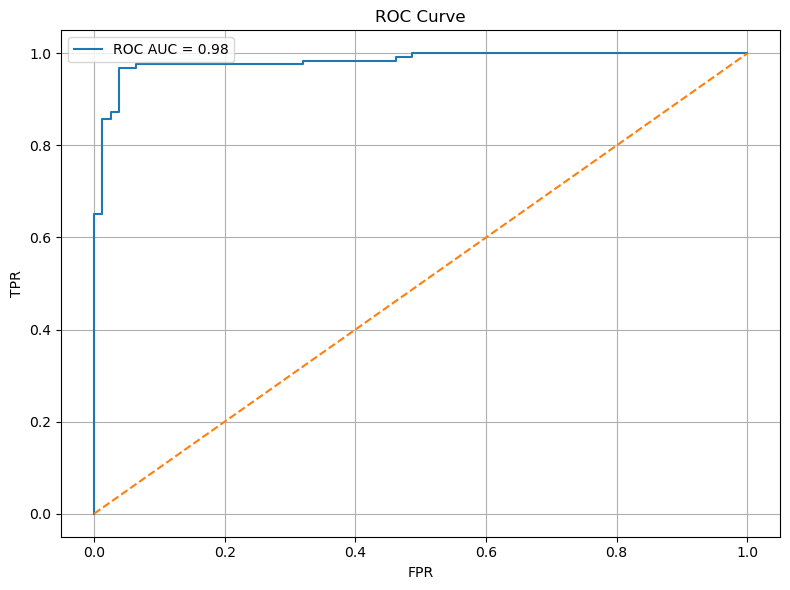

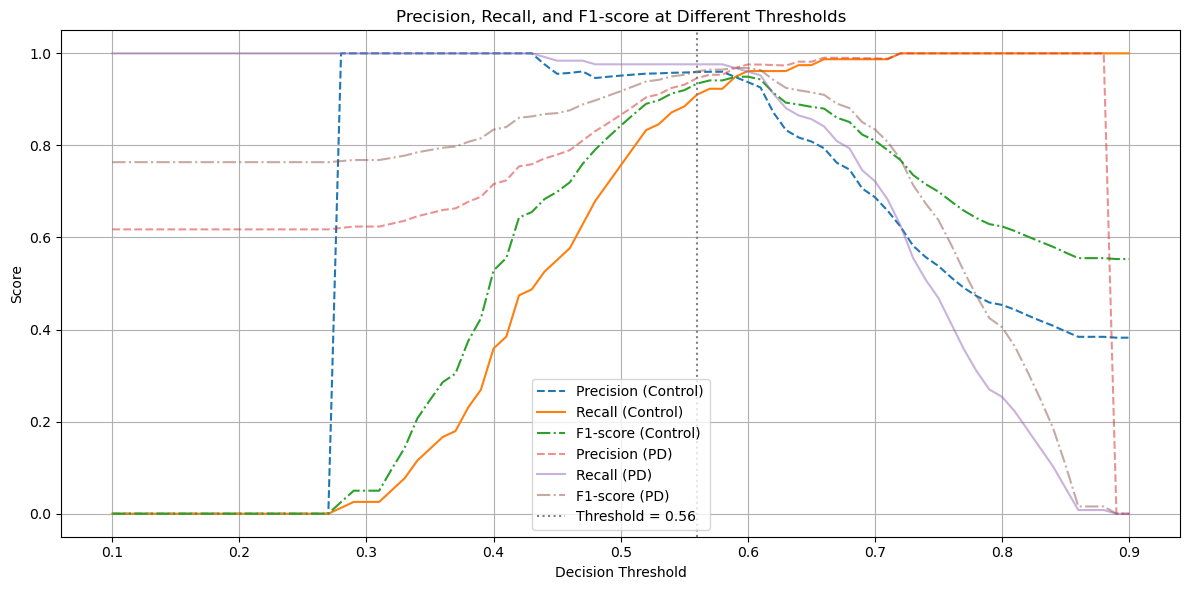

🔵 Auto-detected MDI cutoff (elbow): 0.00099


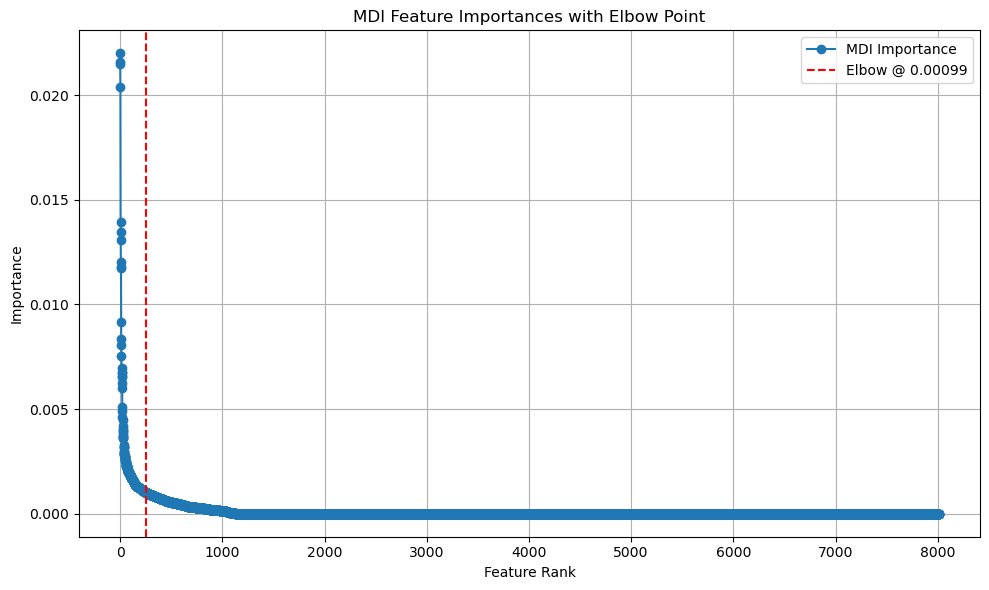

<Figure size 4000x2400 with 0 Axes>

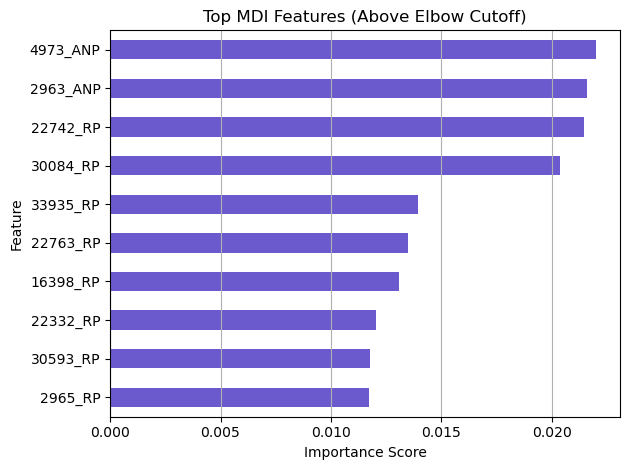

Modeling PD vs RBD
Cross-Validated Classification Report
              precision    recall  f1-score   support

          PD       0.79      0.92      0.85       151
         RBD       0.88      0.71      0.79       126

    accuracy                           0.83       277
   macro avg       0.84      0.82      0.82       277
weighted avg       0.83      0.83      0.82       277

Confusion Matrix:
      PD  RBD
PD   139   12
RBD   36   90
✅ Classification report and confusion matrix exported.
Classification Report at Threshold 0.56
              precision    recall  f1-score   support

          PD       0.71      0.97      0.82       151
         RBD       0.94      0.52      0.67       126

    accuracy                           0.77       277
   macro avg       0.82      0.74      0.74       277
weighted avg       0.81      0.77      0.75       277

✅ Thresholded classification report and confusion matrix exported.


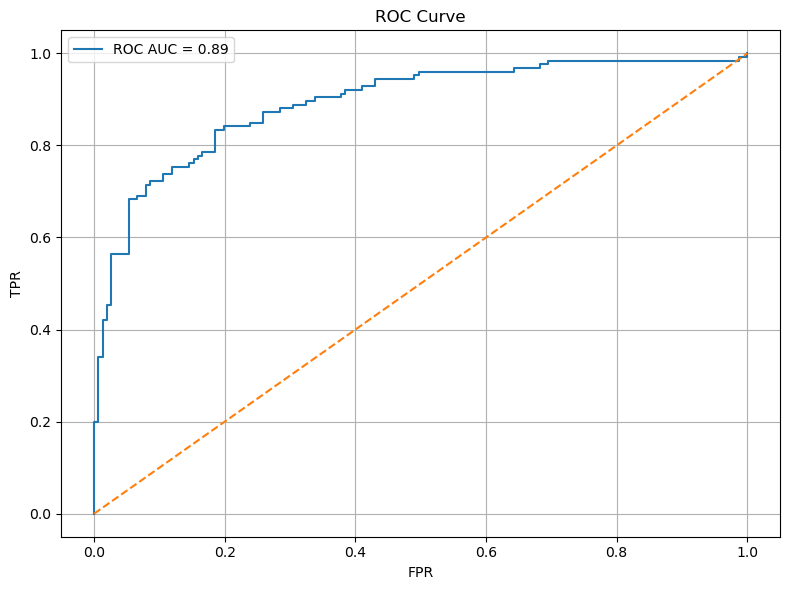

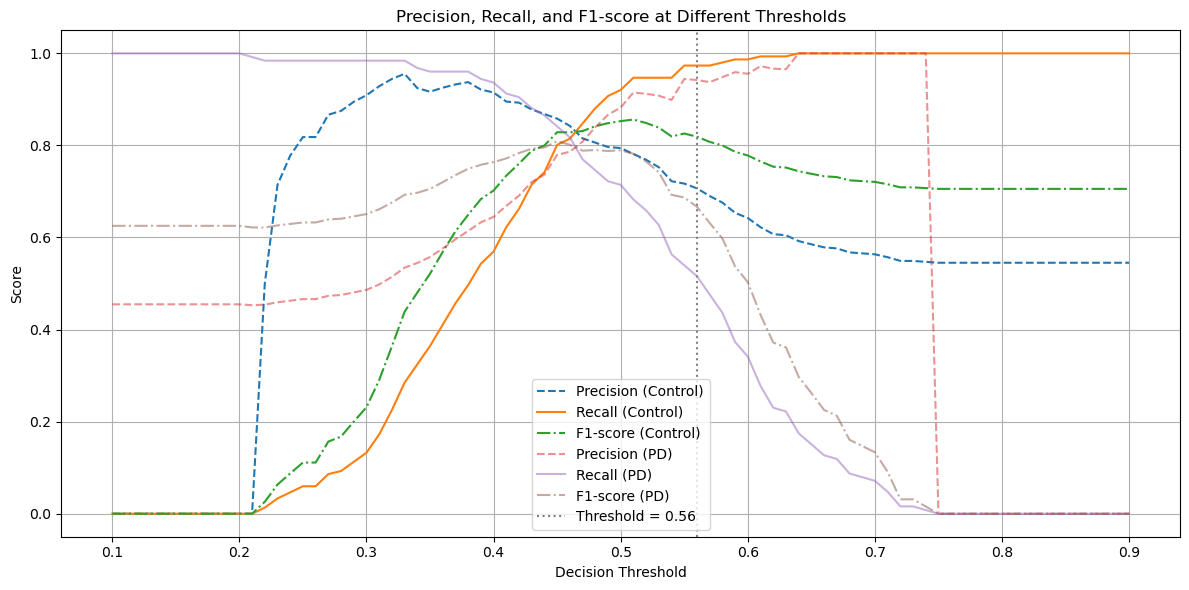

🔵 Auto-detected MDI cutoff (elbow): 0.00087


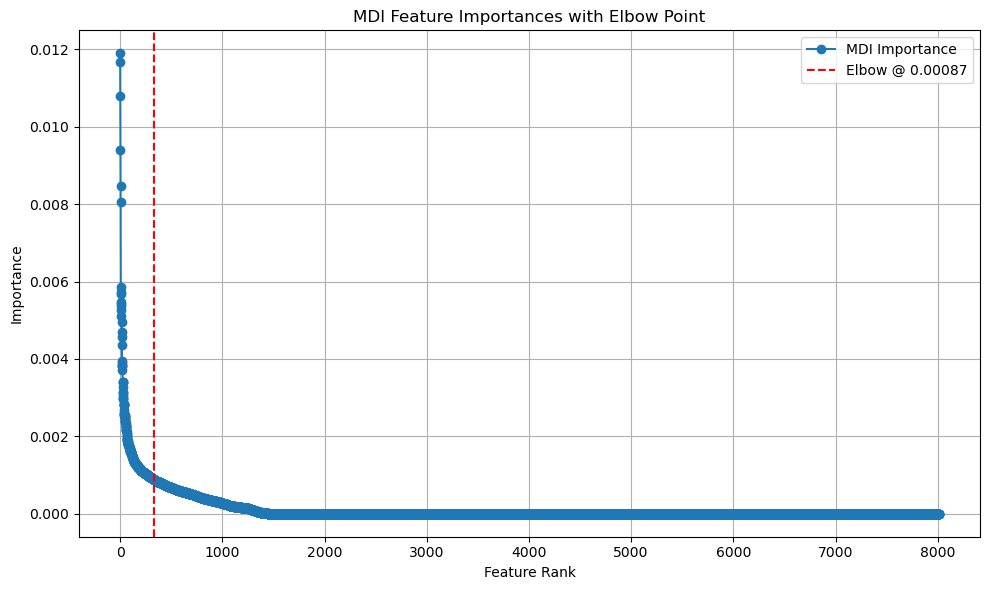

<Figure size 4000x2400 with 0 Axes>

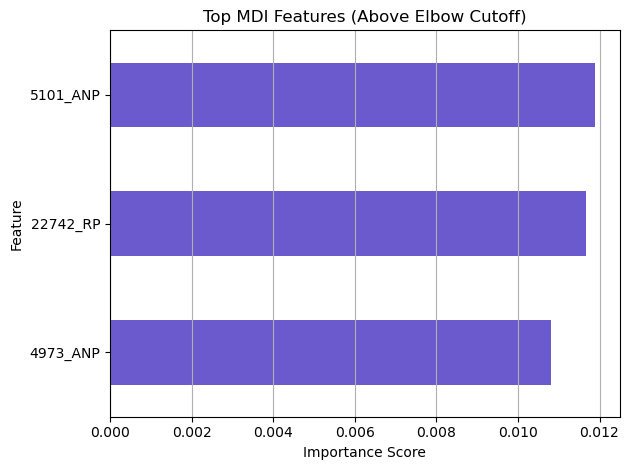

Modeling RBD vs CON
Cross-Validated Classification Report
              precision    recall  f1-score   support

         RBD       0.87      0.59      0.70        78
         CON       0.82      0.95      0.88       151

    accuracy                           0.83       229
   macro avg       0.84      0.77      0.79       229
weighted avg       0.84      0.83      0.82       229

Confusion Matrix:
     RBD  CON
RBD   46   32
CON    7  144
✅ Classification report and confusion matrix exported.
Classification Report at Threshold 0.56
              precision    recall  f1-score   support

         RBD       0.77      0.82      0.80        78
         CON       0.90      0.87      0.89       151

    accuracy                           0.86       229
   macro avg       0.84      0.85      0.84       229
weighted avg       0.86      0.86      0.86       229

✅ Thresholded classification report and confusion matrix exported.


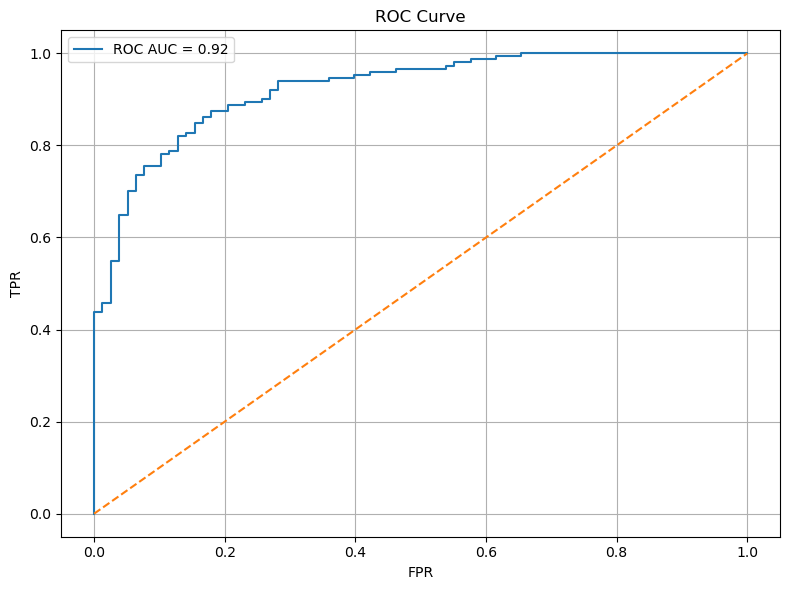

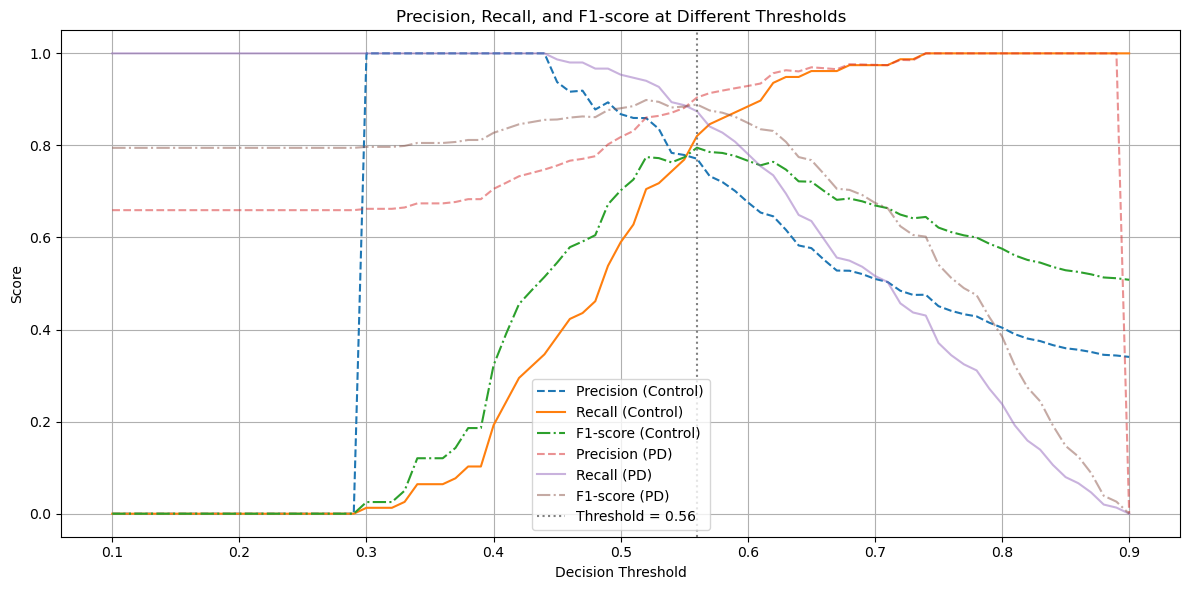

🔵 Auto-detected MDI cutoff (elbow): 0.00088


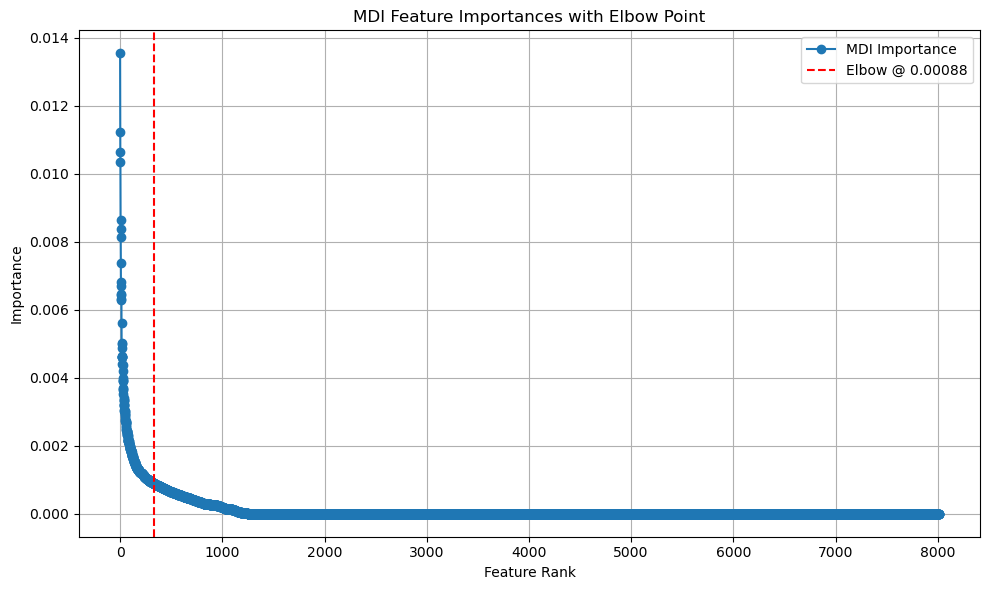

<Figure size 4000x2400 with 0 Axes>

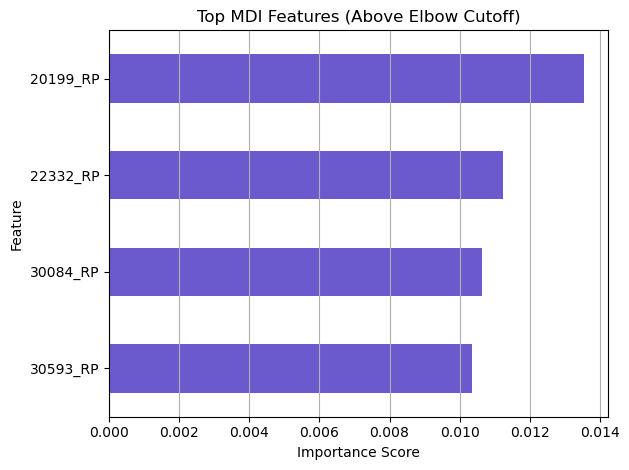

✅ All pairwise modeling completed.
Empty DataFrame
Columns: []
Index: []


In [13]:
pair_to_model = cfg.random_forest.class_pair_to_model

# ? pair_to_model is a variable from PARAMS file with the following possible integer options:
pairs = [
    # 0 -- all 3 pairwise
    ["PD", "CON"], # 1
    ["PD", "RBD"], # 2
    ["RBD", "CON"] # 3
]

if (pair_to_model is None or pair_to_model == 0):
    all_top_filtered = pd.DataFrame()
    for pair in pairs:
        print(f"Modeling {pair[0]} vs {pair[1]}")
        top_filtered = run_rf_pipeline(pair)
        top_filtered.to_csv(get_output_file_name(type="ml", description=f"mdi_top_{pair[0]}_vs_{pair[1]}", ext="csv"), index=False)
    print("✅ All pairwise modeling completed.")
else:
    print(f"Modeling {pairs[pair_to_model - 1][0]} vs {pairs[pair_to_model - 1][1]}.")
    top_filtered = run_rf_pipeline(pairs[pair_to_model - 1])
    top_filtered.to_csv(get_output_file_name(type="ml", description=f"mdi_top_{pairs[pair_to_model - 1][0]}_vs_{pairs[pair_to_model - 1][1]}", ext="csv"), index=False)
    print(f"✅ Pairwise {pairs[pair_to_model - 1][0]} vs {pairs[pair_to_model - 1][1]} modeling completed.")

print(all_top_filtered.head())

In [14]:
# # TODO: Manually define your list of significant feature names
# significant_features = [
#     '22763_RP', '30084_RP', '22733_RP', '22332_RP', '30189_RP',
#     '21610_RP', '30049_RP', '4973_ANP', '20195_RP', '16398_RP',
#     '27049_RP', '22739_RP', '29103_RP', '21389_RP', '15559_RP',
#     '22742_RP', '30593_RP', '30527_RP', '14602_RP', '29123_RP',
#     '11549_ANP', '27427_RP', '4251_ANP', '33935_RP', '6935_ANP',
#     '24678_RP', '22350_ANP', '20199_RP', '32741_RP', '21828_RP',
#     '6561_ANP', '16243_RP', '9860_RP', '10024_ANP', '15494_ANP',
#     '29407_RP', '15359_RP', '23606_RP', '6399_ANP', '6356_ANP',
#     '29893_RP', '9640_RP', '22768_RP', '12573_RP', '14571_RP',
#     '21346_ANP', '9913_ANP', '11828_ANP', '15473_RP', '4550_ANP',
#     '28941_RP', '31585_RP', '27088_RP', '10707_ANP', '20854_RP',
#     '14521_RP', '24340_RP', '20833_RP', '17589_ANP', '28927_RP'
# ]

# # Filter full DataFrame (including group labels)
# filtered_df = df.loc[:, [df.columns[0]] + significant_features]

# # Save filtered file
# filtered_df.to_csv(get_output_file_name(type="output", description="filtered_significant_features", ext="csv"))
# print("✅ Filtered DataFrame with selected significant features saved.")